# F10: Löwdin cutoff, mu units, band trimming, fallback weights (implemented)

**Finding** (`notes/theory_audit.md`, F10) collects smaller items. Only one of them changes results for runs that
worked before:

| item | before | now | legacy switch |
|---|---|---|---|
| Löwdin step (`los_orbs`) | float32, absolute eigenvalue cutoff 1e-15 | float64, cutoff `LOWDIN_RTOL` = 1e-6 × largest eigenvalue, with a warning | `legacy_lowdin_cutoff=True` |
| mu | pymatgen's `outfile.mu / Ha_to_eV`; pymatgen's fallback is already in Hartree | read in Hartree from the last `FillingsUpdate` line after LCAO | none (identical where it worked) |
| `trim_excess_bands` | toggling any setting afterwards raised `IndexError` | re-trims from the full band set; deprecated (`FutureWarning`) | none (bug fix) |
| fallback k-weights | summed to `nspin` (1 for no-spin) | sum to 2, as JDFTx's | kept under `legacy_reduced_kmesh` |

Already settled before this fix: the README's S formula (rewritten with F2), `p_uu_consistent` (only used by the
legacy matrices), and the setter ordering (fixed with F2).

**Why the cutoff matters.** $S_t = P_t^\dagger P_t$ is the overlap of the band-projected orbitals at state $t$. An
orbital combination the bands don't span has an eigenvalue at float32 noise (~1e-8 to 1e-10), whose sign is
random. The old absolute cutoff kept the positive ones and scaled them by $1/\sqrt{\lambda}$, giving pure
noise unit weight, and dropped the negative ones. The figures are saved to `figures/`. The last cell holds the tests.

In [1]:
import sys
import warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))  # fixcompare.py lives next to this notebook (run with this directory as cwd)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from fixcompare import *
from crawfish.funcs import get_ipcohp, get_pcohp, get_ipcobi
from crawfish.core.operations.matrix import los_projs_for_orbs, LOWDIN_RTOL

LEGACY_C, FIXED_C = "#eb6834", "#2a78d6"  # categorical slots 2 and 1 of the default palette
assert fix_available("F10")


def quiet(f, *args, **kwargs):
    """Run f with warnings silenced (the Löwdin warning fires on every graphene load)."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return f(*args, **kwargs)


def smallest_rel_eigs(edata):
    """Smallest eigenvalue of S_t = P_t^dag P_t (raw projections), relative to the largest, per state."""
    raw = quiet(load_edata, edata.calc_dir, los_orbs=False)
    P = np.asarray(raw.proj_tju, dtype=np.complex128)
    out = []
    for t in range(P.shape[0]):
        e = np.linalg.eigvalsh(P[t].conj().T @ P[t])
        out.append(e[0] / e[-1])
    return np.array(out)

## Overlap eigenvalues

The smallest eigenvalue of $S_t$ per state, relative to the largest. N2 (15 bands) and graphene with 20 bands
(`graphene_zspin_full`) sit far above the cutoff, apart from 4 states at K in graphene, where one in-plane σ
combination lies above all 20 bands. `graphene_1x1` has 8 bands for 8 orbitals, so its smallest eigenvalue
spreads continuously down to the noise floor. That is finding F11 (too few bands); the cutoff only stops the
noise from being amplified.

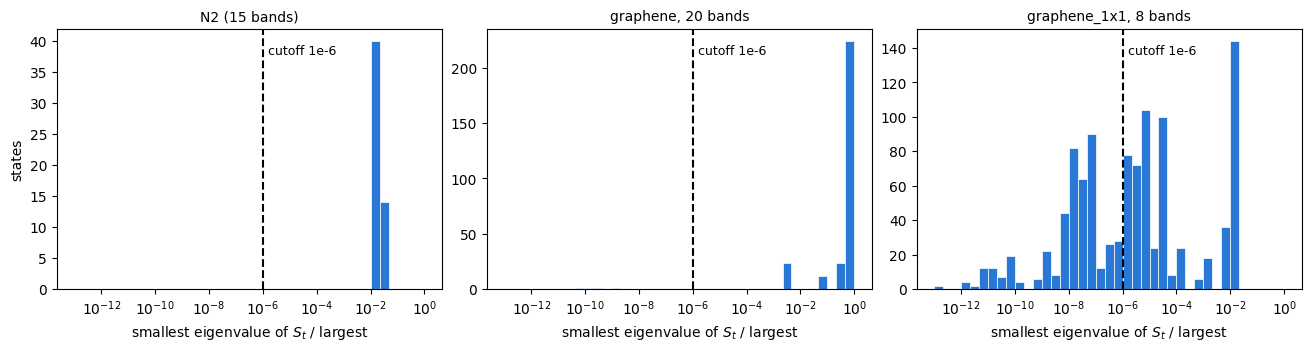

,states,below 1e-6 (now dropped),kept by old cutoff (1e-15 < x < 1e-6)
N2 (15 bands),54,0,0
"graphene, 20 bands",288,4,4
"graphene_1x1, 8 bands",1058,444,444


In [2]:
systems = {"N2 (15 bands)": N2_CALC_DIR,
           "graphene, 20 bands": Path(EXAMPLE_CALC_DIRS_DIR) / "graphene_zspin_full",
           "graphene_1x1, 8 bands": GRAPHENE_CALC_DIR}
eigs = {name: smallest_rel_eigs(quiet(load_edata, d)) for name, d in systems.items()}

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharex=True, layout="constrained")
bins = np.logspace(-13, 0, 40)
for ax, (name, r) in zip(axes, eigs.items()):
    ax.hist(np.clip(r, 1e-13, None), bins=bins, color=FIXED_C, edgecolor="white", linewidth=0.5)
    ax.axvline(LOWDIN_RTOL, color="black", linewidth=1.5, linestyle="--")
    ax.text(LOWDIN_RTOL * 1.6, ax.get_ylim()[1] * 0.9, "cutoff 1e-6", fontsize=9)
    ax.set_xscale("log")
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("smallest eigenvalue of $S_t$ / largest")
axes[0].set_ylabel("states")
savefig(fig, "F10_overlap_eigenvalues")
plt.show()

pd.DataFrame({name: {"states": len(r), "below 1e-6 (now dropped)": int(np.sum(r < LOWDIN_RTOL)),
                     "kept by old cutoff (1e-15 < x < 1e-6)": int(np.sum((r > 1e-15) & (r < LOWDIN_RTOL)))}
              for name, r in eigs.items()}).T

## The old cutoff depended on the sign of the noise

Synthetic projections with one direction of eigenvalue λ (ten random bases each). Below float32 resolution
(λ ≲ 1e-7), the legacy step drops the direction in some bases and amplifies it in others. The relative cutoff
always drops it.

In [3]:
def synthetic(eig_small, seed):
    rng = np.random.default_rng(seed)
    u, _ = np.linalg.qr(rng.normal(size=(6, 4)) + 1j * rng.normal(size=(6, 4)))
    v, _ = np.linalg.qr(rng.normal(size=(4, 4)) + 1j * rng.normal(size=(4, 4)))
    return (u * np.sqrt([1.0, 0.8, 0.5, eig_small])) @ v.conj().T

rows = {}
for lam in [1e-10, 1e-9, 1e-8, 1e-7, 5e-7, 1e-5]:
    P = np.array([synthetic(lam, s) for s in range(10)], dtype=np.complex64)
    rows[f"{lam:g}"] = {"legacy: dropped in N of 10": int(np.sum(los_projs_for_orbs(P, legacy=True, return_ndropped=True)[1])),
                        "fixed: dropped in N of 10": int(np.sum(los_projs_for_orbs(P, return_ndropped=True)[1]))}
noise_table = pd.DataFrame(rows).T
noise_table.index.name = "λ"
noise_table

,legacy: dropped in N of 10,fixed: dropped in N of 10
λ,,
1e-10,5,10
1e-09,2,10
1e-08,4,10
1e-07,0,10
5e-07,0,10
1e-05,0,0


## Graphene: three equivalent bonds

In `graphene_1x1`, C1 has three nearest C2 images (R = (−1,−1,0), (0,−1,0), (0,0,0); see F3). They are
equivalent by symmetry (up to 0.003 Å of relaxation), so their all-orbital IpCOHP should agree. Both sides use
every earlier fix (`load_edata_at`).

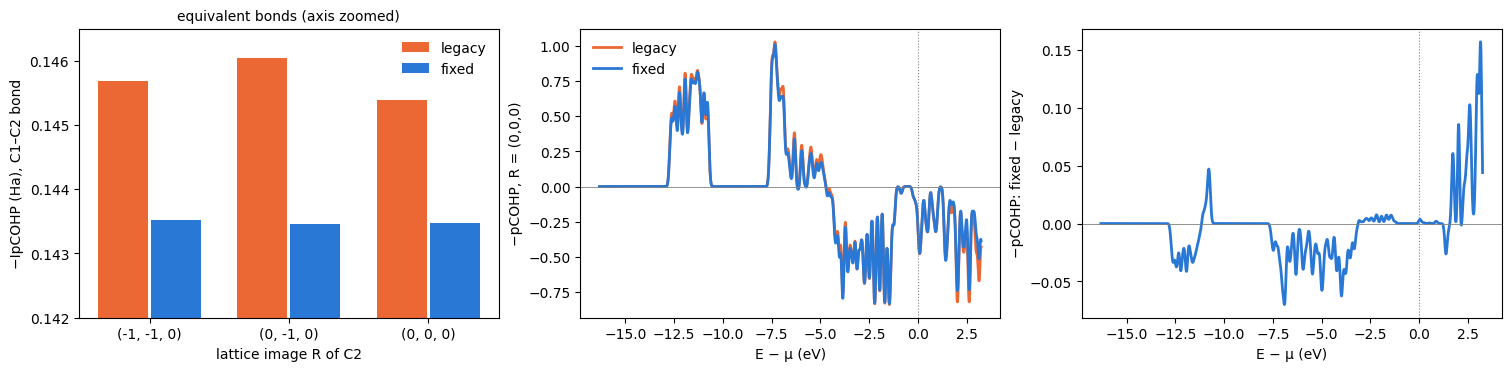

,legacy,fixed
R,,
"(-1, -1, 0)",-0.145688,-0.143520
"(0, -1, 0)",-0.146043,-0.143459
"(0, 0, 0)",-0.145390,-0.143475
spread (max − min),0.000653,0.000061


In [4]:
BONDS = [(-1, -1, 0), (0, -1, 0), (0, 0, 0)]
gr = {"legacy": quiet(load_edata_at, "F10", fixed=False, calc_dir=GRAPHENE_CALC_DIR),
      "fixed": quiet(load_edata_at, "F10", fixed=True, calc_dir=GRAPHENE_CALC_DIR)}
bond_ipcohp = pd.DataFrame({name: [last_value(get_ipcohp(ed, idcs1=0, idcs2=1, image=list(R))) for R in BONDS]
                            for name, ed in gr.items()}, index=[str(R) for R in BONDS])
bond_ipcohp.index.name = "R"

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), layout="constrained")
x = np.arange(len(BONDS))
for i, (name, c) in enumerate([("legacy", LEGACY_C), ("fixed", FIXED_C)]):
    axes[0].bar(x + (i - 0.5) * 0.38, -bond_ipcohp[name], 0.36, color=c, label=name)
axes[0].set_xticks(x, [str(R) for R in BONDS])
axes[0].set_ylim(0.142, 0.1465)
axes[0].set_ylabel("−IpCOHP (Ha), C1–C2 bond")
axes[0].set_xlabel("lattice image R of C2")
axes[0].legend(frameon=False)
axes[0].set_title("equivalent bonds (axis zoomed)", fontsize=10)

# Valence window only: this fixture also has two flat bands near -3 Ha (JDFTx's own eigStats: eMin -3.315 Ha)
mu = gr["fixed"].mu
erange = np.arange(mu - 0.6, mu + 0.12, 0.0005, dtype=np.float32)
x_ev = to_ev_rel_mu(gr["fixed"], erange)
specs = {name: -np.ravel(get_pcohp(gr[name], idcs1=0, idcs2=1, image=list(BONDS[2]), erange=erange)[1])
         for name in gr}
for name, c in [("legacy", LEGACY_C), ("fixed", FIXED_C)]:
    axes[1].plot(x_ev, specs[name], color=c, linewidth=2, label=name)
axes[1].set_ylabel("−pCOHP, R = (0,0,0)")
axes[1].legend(frameon=False)
axes[2].plot(x_ev, specs["fixed"] - specs["legacy"], color=FIXED_C, linewidth=2)
axes[2].set_ylabel("−pCOHP: fixed − legacy")
for ax in axes[1:]:
    ax.axvline(0, color="gray", linewidth=0.8, linestyle=":")
    ax.axhline(0, color="gray", linewidth=0.6)
    ax.set_xlabel("E − μ (eV)")
savefig(fig, "F10_graphene_bonds")
plt.show()

bond_ipcohp.loc["spread (max − min)"] = bond_ipcohp.max() - bond_ipcohp.min()
bond_ipcohp

## N2 is unchanged

The bands span every orbital at every state, so nothing is dropped and only float32 rounding separates the two.

In [5]:
n2 = {"legacy": quiet(load_edata_at, "F10", fixed=False), "fixed": quiet(load_edata_at, "F10", fixed=True)}
PAIRS = [(None, None), ("s", "s"), ("s", "px"), ("px", "px"), ("py", "py")]
n2_table = pd.DataFrame({name: [last_value(get_ipcohp(ed, idcs1=0, idcs2=1, orbs1=a, orbs2=b)) for a, b in PAIRS]
                         for name, ed in n2.items()}, index=[f"{a or 'all'}–{b or 'all'}" for a, b in PAIRS])
n2_table["difference"] = n2_table["fixed"] - n2_table["legacy"]
n2_table

,legacy,fixed,difference
all–all,-0.866777,-0.866777,5.960464e-08
s–s,-0.111312,-0.111312,-7.450581e-09
s–px,-0.139357,-0.139357,4.470348e-08
px–px,-0.118154,-0.118154,4.470348e-08
py–py,-0.179305,-0.179305,0.000000e+00


## mu in Hartree from the outfile

crawfish now reads the last `FillingsUpdate` line after LCAO itself. Where pymatgen's main path gives a mu, the
two agree. Without `elec-smearing`, JDFTx prints `FillingsUpdate` only during LCAO (which uses its own smearing),
so there is no converged mu. pymatgen then fills a fallback, `_mu_backup`, in Hartree, while `outfile.mu` is
otherwise in eV. crawfish used to divide `outfile.mu` by `Ha_to_eV` unconditionally.

In [6]:
from crawfish.io.data_parsing import get_mu_from_outfile_filepath
from pymatgen.io.jdftx.outputs import JDFTXOutfile
from pymatgen.core.units import Ha_to_eV

rows = {}
for name in ["Al_fcc_Fermi", "Al_fcc_MP1", "N2_bare_min", "N2_nospin", "graphene_1x1", "Si_nosmear_nospin"]:
    out = Path(EXAMPLE_CALC_DIRS_DIR) / name / "out"
    pm = quiet(JDFTXOutfile.from_file, out)
    rows[name] = {"crawfish (Ha)": get_mu_from_outfile_filepath(out),
                  "pymatgen outfile.mu / Ha_to_eV": None if pm.mu is None else pm.mu / Ha_to_eV,
                  "pymatgen _mu_backup (Ha, LCAO)": pm.slices[-1]._mu_backup}
mu_table = pd.DataFrame(rows).T
mu_table

,crawfish (Ha),pymatgen outfile.mu / Ha_to_eV,"pymatgen _mu_backup (Ha, LCAO)"
Al_fcc_Fermi,0.285482,0.285482,NaN
Al_fcc_MP1,0.285176,0.285176,NaN
N2_bare_min,-0.095776,-0.095776,NaN
N2_nospin,-0.100000,-0.100000,NaN
graphene_1x1,-0.069873,-0.069873,NaN
Si_nosmear_nospin,NaN,NaN,0.267051


## `trim_excess_bands` and the fallback weights

Before this fix, toggling any setting after `trim_excess_bands = True` re-trimmed the reloaded projections but
indexed the already-trimmed eigenvalues and occupations, which raised `IndexError` (or mismatched silently when
switching trimming off again). The setting is now deprecated, because it keeps the same bands at every k
(ranked by Σ|T| over all k) and rescales |T|² non-unitarily.

In [7]:
ed = quiet(load_edata)
e_full = np.array(ed.e_tj)
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    ed.trim_excess_bands = True
deprecation = [str(w.message)[:60] for w in caught if issubclass(w.category, FutureWarning)]
ed.los_orbs = False  # raised IndexError before
ed.los_orbs = True
quiet(setattr, ed, "trim_excess_bands", False)
trim_ok = np.array_equal(ed.e_tj, e_full) and ed.proj_tju.shape[1] == e_full.shape[1]

from crawfish.io.data_parsing import _get_arbitrary_wk
wk_table = pd.DataFrame({f"nspin={n}": {"fixed sum": _get_arbitrary_wk(4, n).sum(),
                                        "legacy sum": _get_arbitrary_wk(4, n, legacy=True).sum()} for n in (1, 2)})
print("deprecation warning:", deprecation)
print("e_tj restored after trimming off:", trim_ok)
wk_table

deprecation warning: ['trim_excess_bands is deprecated. It keeps the same nproj ban']
e_tj restored after trimming off: True


/Users/richb/vs/crawfish/src/crawfish/core/elecdata.py:521: UserWarning: Löwdin orthonormalization (los_orbs) dropped 12 orbital combination(s) at 12 of 54 states: the bands span them with an overlap eigenvalue below 1e-06 of the largest, so they get no weight there. Pair spectra involving those orbitals miss that part of the interaction. Check edata.orbital_completeness_u; more elec-n-bands usually fixes this (notes/theory_audit.md, findings F10 and F11).
  self.alloc_elec_data()


,nspin=1,nspin=2
fixed sum,2.0,2.0
legacy sum,1.0,2.0


## Tests

In [8]:
# Löwdin cutoff
assert eigs["N2 (15 bands)"].min() > 1e-3 and np.sum(eigs["graphene, 20 bands"] < LOWDIN_RTOL) == 4
assert np.sum(eigs["graphene_1x1, 8 bands"] < LOWDIN_RTOL) > 300
assert (noise_table["fixed: dropped in N of 10"].loc[["1e-10", "1e-09", "1e-08", "1e-07", "5e-07"]] == 10).all()
assert (noise_table["fixed: dropped in N of 10"].loc[["1e-05"]] == 0).all()
assert 0 < noise_table.loc["1e-08", "legacy: dropped in N of 10"] < 10  # noise sign decides
spread = bond_ipcohp.loc["spread (max − min)"]
assert spread["fixed"] < 1e-4 < 5e-4 < spread["legacy"]
assert np.allclose(bond_ipcohp["legacy"].iloc[:3], [-0.14569, -0.14604, -0.14539], atol=2e-5)
assert np.allclose(bond_ipcohp["fixed"].iloc[:3], [-0.14352, -0.14346, -0.14348], atol=2e-5)
assert np.abs(n2_table["difference"]).max() < 1e-5
# mu
both = mu_table.dropna(subset=["pymatgen outfile.mu / Ha_to_eV"])
assert np.allclose(both["crawfish (Ha)"].astype(float), both["pymatgen outfile.mu / Ha_to_eV"].astype(float), atol=1e-15)
assert pd.isna(mu_table.loc["Si_nosmear_nospin", "crawfish (Ha)"])
assert mu_table.loc["Si_nosmear_nospin", "pymatgen _mu_backup (Ha, LCAO)"] > 0.2  # Hartree, not eV
# trimming and weights
assert deprecation and trim_ok
assert np.allclose(wk_table.loc["fixed sum"], 2) and np.allclose(wk_table.loc["legacy sum"], [1, 2])
print("All F10 checks passed.")

All F10 checks passed.
